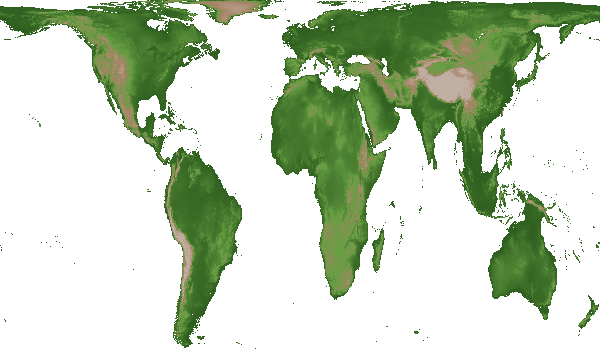

Image dimensions: 600x351 pixels


In [1]:
# first load image and show with pil
from PIL import Image
from IPython.display import display

# Load the image
image_path = "ch1_map.png"
image = Image.open(image_path)
image = image.convert("RGBA")  # Ensure it's in RGBA format
# Display the image
display(image)
# print dimensions of the image
print(f"Image dimensions: {image.size[0]}x{image.size[1]} pixels")


Binary matrix shape: (351, 600)
First 10 rows of the binary matrix:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]


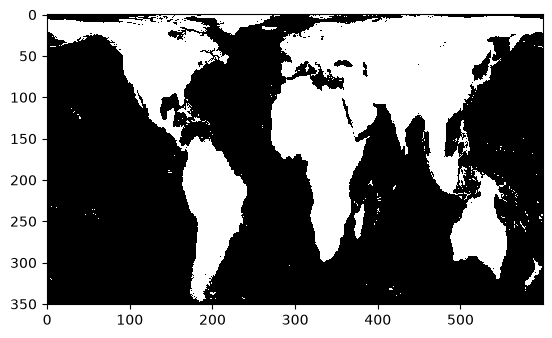

In [2]:
# make a matrix with similar dimensions such that all white pixels are 0 and all other pixels are 1
import numpy as np
# Convert the image to a numpy array
image_array = np.array(image)
# Create a mask where white pixels are 0 and all other pixels are 1
mask = np.all(image_array[:, :, :3] == [255, 255, 255], axis=-1)
# Convert the mask to a binary matrix
binary_matrix = np.where(mask, 0, 1)
# Print the shape of the binary matrix
print(f"Binary matrix shape: {binary_matrix.shape}")
# Print the first 10 rows of the binary matrix
print("First 10 rows of the binary matrix:")
print(binary_matrix[:10])
# show as black white image
import matplotlib.pyplot as plt
plt.imshow(binary_matrix, cmap='gray', interpolation='nearest')

In [3]:
# Boolean land mask: True = land, False = sea. Indexed as LAND[y, x] (row, column).
LAND = binary_matrix.astype(bool)

# Background map as a plain RGB array, loaded once so it isn't re-read every frame.
BG = np.array(Image.open("ch1_map.png").convert("RGB"))

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import mesa
from mesa.discrete_space import CellAgent, OrthogonalMooreGrid
from mesa.visualization import SolaraViz, make_plot_component, make_space_component

class DispersalAgent(CellAgent):
    def __init__(self, model, cell, growth_rate):
        super().__init__(model)
        self.cell = cell
        self.growth_rate = growth_rate
        # mark cell as taken and add to frontier (item 3)
        x, y = cell.coordinate
        model.occupied[y, x] = True
        model.frontier.add(self)

    def hatch(self):  # 4 spaces in, same level as __init__
        # free land neighbours only
        options = [c for c in self.cell.neighborhood.cells
                   if LAND[c.coordinate[1], c.coordinate[0]]
                   and not self.model.occupied[c.coordinate[1], c.coordinate[0]]]
        # enclosed: drop from frontier for good
        if not options:
            self.model.frontier.discard(self)
            return
        # hatch with probability growth_rate
        if self.random.random() < self.growth_rate:
            DispersalAgent(self.model, self.random.choice(options), self.growth_rate)

class DispersalModel(mesa.Model):
    """A model with a grid of cells and agents that can occupy them."""

    def __init__(self, n=10, width=600, height=351, seed=None, growth_rate=0.1):
        # width/height must match the image (600 x 351), or indexing LAND fails.
        """Initialize the model instance
        
        Args:            
            n (int): Number of agents to create.
            width (int): Width of the grid.
            height (int): Height of the grid.
            seed (int, optional): Random seed for reproducibility.
        """
        super().__init__(seed=seed)
        self.num_agents = n
        self.grid = OrthogonalMooreGrid(dimensions=(width, height), torus=True, random=self.random)
        # Occupancy array, same shape as the map: True where an agent sits.
        # Must exist before any agent is created, because agents write to it.
        self.occupied = np.zeros((height, width), dtype=bool)

        # Agents that might still hatch. Only these get stepped.
        self.frontier = set()

        # Create cells and agents
        possible_positions = self.grid.all_cells.cells
        # Only select from a specific rectangular area
        min_x,min_y, max_x, max_y = 350, 150, 370, 170
        # filter the possible positions to only those within the specified rectangle
        filtered_possible_positions = [cell for cell in possible_positions
                                       if min_x <= cell.coordinate[0] <= max_x and
                                            min_y <= cell.coordinate[1] <= max_y and
                                             LAND[cell.coordinate[1], cell.coordinate[0]]]
        
        DispersalAgent.create_agents(model=self,
                                     n=self.num_agents, 
                                     growth_rate=growth_rate,
                                    # sample() picks without replacement: no two agents on one cell.
                                     cell=self.random.sample(filtered_possible_positions, k=self.num_agents),)
        
    def step(self):
        """Advance the model by one step."""
                # Copy the frontier to a list, because agents remove themselves
        # (and new ones are added) while we loop.
        active = list(self.frontier)

        # Random order so no agent systematically gets first pick of free cells.
        self.random.shuffle(active)

        # Only frontier agents act; enclosed agents are skipped entirely.
        for a in active:
            a.hatch()

In [12]:
model = DispersalModel(n=10, width=600, height=351)
for _ in range(1):
    model.step()


In [13]:
# Model parameters for visualization
model_params = {
    "n": {
        "type": "SliderInt",
        "value": 20,
        "label": "Number of agents:",
        "min": 5,
        "max": 100,
        "step": 1,
    },
    "growth_rate": {
        "type": "SliderFloat",
        "value": 0.1,
        "label": "Growth rate:",
        "min": 0.0,
        "max": 0.5,
        "step": 0.02,
    },
    "width": 600,   # For testing, use smaller grid
    "height": 351,  # For full size, use 600x351
}



In [14]:
# Load image ONCE at module level (outside the component)
from PIL import Image
import matplotlib.pyplot as plt
import solara

# Load the image once when the module is imported
image_path = "ch1_map.png"
BACKGROUND_IMAGE = Image.open(image_path)

@solara.component
def CustomSpaceVisualization(model):
    """Custom space visualization with map image background"""
        # Subscribing to the update counter makes Solara redraw after each step.
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()

    # Figure (not pyplot) avoids global state; low dpi keeps rendering fast.
    fig = plt.Figure(figsize=(8, 4.7), dpi=80)
    ax = fig.subplots()

    # Draw the map in pixel coordinates: column = x, row = y (row 0 at the top).
    ax.imshow(BG, interpolation="nearest")

    # Transparent RGBA layer the same size as the map.
    overlay = np.zeros((*model.occupied.shape, 4))

    # Colour occupied cells red (alpha 0.9). Each agent is exactly one map pixel,
    # so it lines up with the background by construction.
    overlay[model.occupied] = (1, 0, 0, 0.9)

    # Draw agents on top: one image instead of thousands of scatter markers.
    ax.imshow(overlay, interpolation="nearest")

    # Agent count straight from the occupancy array.
    ax.set_title(f"Dispersal Model - {int(model.occupied.sum())} agents", fontsize=10)

    # Pixel axes add nothing here, so hide them.
    ax.axis("off")
    solara.FigureMatplotlib(fig)

In [15]:

page = SolaraViz(
    model,
    components=[CustomSpaceVisualization],
    model_params=model_params,
    name="Dispersal",
)


# Custom visualization
Below is an example of a custom space that interfaces with the picture.

In [16]:
page


Cannot show ipywidgets in text

In [21]:
# Creating A GIF
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def create_dispersal_gif(model, num_steps=100, filename="dispersal_animation.gif", fps=10):
    """Create a GIF animation of the dispersal model.
    Args:
        model: The DispersalModel instance
        num_steps: Number of steps to simulate
        filename: Output filename for the GIF
        fps: Frames per second for the GIF
    """
    frames = []

    for step in range(num_steps):
        # Create figure
        fig = plt.figure(figsize=(10, 6), dpi=100)
        ax = fig.add_subplot(111)

        # Map in pixel coordinates: column = x, row = y (row 0 at top), same as the model
        ax.imshow(BG, interpolation="nearest")

        # Transparent RGBA layer, same size as the map
        overlay = np.zeros((*model.occupied.shape, 4))
        # Occupied cells in red; one agent = exactly one map pixel, so it aligns by construction
        overlay[model.occupied] = (1, 0, 0, 0.9)
        # Draw agents on top of the map
        ax.imshow(overlay, interpolation="nearest")

        # Agent count from the occupancy array
        n_agents = int(model.occupied.sum())
        ax.set_title(f'Dispersal Model - Step {step} - {n_agents} agents', fontsize=12)
        # Pixel axes add nothing here (and y counts downward), so hide them
        ax.axis("off")

        # Convert plot to image: read RGBA and drop the alpha channel
        fig.canvas.draw()
        image = np.asarray(fig.canvas.buffer_rgba())[..., :3]
        frames.append(Image.fromarray(image))
        plt.close(fig)  # free memory, otherwise 100 open figures pile up

        # Step the model
        model.step()

        # Print progress
        if (step + 1) % 10 == 0:
            print(f"Generated frame {step + 1}/{num_steps}")

    # Save as GIF
    duration = int(1000 / fps)  # Duration per frame in milliseconds
    frames[0].save(
        filename,
        save_all=True,
        append_images=frames[1:],
        duration=duration,
        loop=0  # 0 means infinite loop
    )
    print(f"GIF saved as {filename}")
    return frames

# Usage:
# Create a fresh model
model = DispersalModel(n=20, width=600, height=351, growth_rate=0.1, seed=42)

# Create the GIF
frames = create_dispersal_gif(model, num_steps=100, filename="dispersal_spread.gif", fps=10)

Generated frame 10/100
Generated frame 20/100
Generated frame 30/100
Generated frame 40/100
Generated frame 50/100
Generated frame 60/100
Generated frame 70/100
Generated frame 80/100
Generated frame 90/100
Generated frame 100/100
GIF saved as dispersal_spread.gif
